# Model 8: Avocado price prediction with random forest regression

### Authors
   * Jonathan Sancho Loaiza
   * Jennifer Lopez Miranda
   * Magdaleno Gomez Diaz

## Problem Analysis (CRISP-DM 1: Business Understanding)

The retail price of a Hass avocado in the United States moves every week, and it moves differently in every city, in every season and between conventional and organic fruit. A grocer deciding how much to order, or a restaurant deciding whether guacamole stays on the menu next month, wants to know what a single avocado will cost in their region next week. The question this notebook answers is whether that weekly price can be predicted from the type of avocado, the region, the time of year and the quantities sold, well enough for the assistant of the project to give a price when asked.

The dataset is the avocado prices file published on Kaggle by Justin Kiggins, built from the retail scan data of the Hass Avocado Board. Each row is one week in one region for one type of avocado, from January 2015 to March 2018, with the average retail price of a single avocado in dollars and the volume sold, broken down by the three Hass size codes and by bag size.

The technique is the random forest, taught in week six. A single decision tree splits the rows again and again on the predictor that best separates the price, and a forest grows many trees on different random samples of the rows and of the predictors and averages their answers. A tree on its own memorises the data it was grown on, and the average of many trees, each of them slightly wrong in a different way, is far more stable. The notebook grows a single tree first, shows that it memorises, and then grows the forest.

### Libraries

In [1]:
# Dataset handling
import os
import kagglehub
import numpy as np
import pandas as pd

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Models
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Split, evaluation and persistence
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import joblib

%matplotlib inline

RANDOM_STATE = 42

# Folder shared by every model of the project, read later by the REST API
MODELS_DIR = os.path.join('..', '..', 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

/home/jony/ai-project/env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Understanding (CRISP-DM 2)

The dataset is downloaded through kagglehub, which caches it locally and returns the folder, so the same cell works on a local machine and in Google Colab.

In [2]:
path = kagglehub.dataset_download('neuromusic/avocado-prices')
print('Path to dataset files:', path)
avocado = pd.read_csv(os.path.join(path, 'avocado.csv'))
avocado.head()

Path to dataset files: /home/jony/.cache/kagglehub/datasets/neuromusic/avocado-prices/versions/1


,Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany


Each row is one week of sales of one type of avocado in one region. `Date` is the last day of the week, `AveragePrice` the average retail price of one avocado in dollars and the target of this notebook, `Total Volume` the number of avocados sold, and `4046`, `4225` and `4770` the volumes sold under each of the three price look-up codes of Hass avocados, which are the small, large and extra large fruit. `Total Bags` and the three bag columns count the avocados sold in bags rather than loose. `type` is conventional or organic, `year` the year, and `region` the city or area. The first column, `Unnamed: 0`, is a row counter that restarts at every region and carries no information. The first rows are Albany at the end of 2015, with a conventional avocado at 1.33 dollars.

In [3]:
print("Rows and columns:", avocado.shape)
avocado.info()
print("Duplicated rows:", avocado.duplicated().sum())
print("Missing cells:", avocado.isna().sum().sum())

Rows and columns: (18249, 14)
<class 'pandas.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    18249 non-null  int64  
 1   Date          18249 non-null  str    
 2   AveragePrice  18249 non-null  float64
 3   Total Volume  18249 non-null  float64
 4   4046          18249 non-null  float64
 5   4225          18249 non-null  float64
 6   4770          18249 non-null  float64
 7   Total Bags    18249 non-null  float64
 8   Small Bags    18249 non-null  float64
 9   Large Bags    18249 non-null  float64
 10  XLarge Bags   18249 non-null  float64
 11  type          18249 non-null  str    
 12  year          18249 non-null  int64  
 13  region        18249 non-null  str    
dtypes: float64(9), int64(2), str(3)
memory usage: 1.9 MB
Duplicated rows: 0
Missing cells: 0


There are 18,249 rows and 14 columns, no missing cell and no duplicated row. `Date`, `type` and `region` are text and will be converted, the rest is numeric. The file is complete because it comes from a scanner feed, not from a survey.

In [4]:
avocado = avocado.drop(columns=['Unnamed: 0'])
avocado.describe().round(2)

,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,year
count,18249.00,18249.00,18249.00,18249.00,18249.00,18249.00,18249.00,18249.00,18249.00,18249.00
mean,1.41,850644.01,293008.42,295154.57,22839.74,239639.20,182194.69,54338.09,3106.43,2016.15
std,0.40,3453545.36,1264989.08,1204120.40,107464.07,986242.40,746178.51,243965.96,17692.89,0.94
min,0.44,84.56,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2015.00
25%,1.10,10838.58,854.07,3008.78,0.00,5088.64,2849.42,127.47,0.00,2015.00
50%,1.37,107376.76,8645.30,29061.02,184.99,39743.83,26362.82,2647.71,0.00,2016.00
75%,1.66,432962.29,111020.20,150206.86,6243.42,110783.37,83337.67,22029.25,132.50,2017.00
max,3.25,62505646.52,22743616.17,20470572.61,2546439.11,19373134.37,13384586.80,5719096.61,551693.65,2018.00


The price runs from 0.44 to 3.25 dollars with a mean of 1.41 and a median of 1.37, so it is balanced with a modest tail to the right. The volumes are another matter: `Total Volume` has a median of 107,000 avocados but a mean of 851,000 and a maximum of 62.5 million, because the file mixes single cities with aggregates such as the whole country, which is the row of 62 million. Several volume columns have a median of 0, since extra large avocados and extra large bags are rarely sold at all. For a tree-based model this spread is harmless, because a tree only asks whether a value is above or below a cut and does not care how far above.

In [5]:
print(avocado['type'].value_counts())
print()
print("Distinct regions:", avocado['region'].nunique())
print(avocado['year'].value_counts().sort_index())
avocado['Date'] = pd.to_datetime(avocado['Date'])
print("First week:", avocado['Date'].min().date(), " Last week:", avocado['Date'].max().date())

type
conventional    9126
organic         9123
Name: count, dtype: int64

Distinct regions: 54
year
2015    5615
2016    5616
2017    5722
2018    1296
Name: count, dtype: int64
First week: 2015-01-04  Last week: 2018-03-25


The two types are almost exactly balanced, 9,126 conventional rows and 9,123 organic, since every region reports both every week. There are 54 regions, and the years 2015, 2016 and 2017 have around 5,600 rows each while 2018 has 1,296, because the file ends on the 25th of March 2018. That last fact matters later: the model will have seen only twelve weeks of 2018.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

The exploration asks which of the available facts move the price, starting with the type, then the calendar, then the region and finally the volumes.

               mean  median    std  count
type                                     
conventional  1.158    1.13  0.263   9126
organic       1.654    1.63  0.364   9123


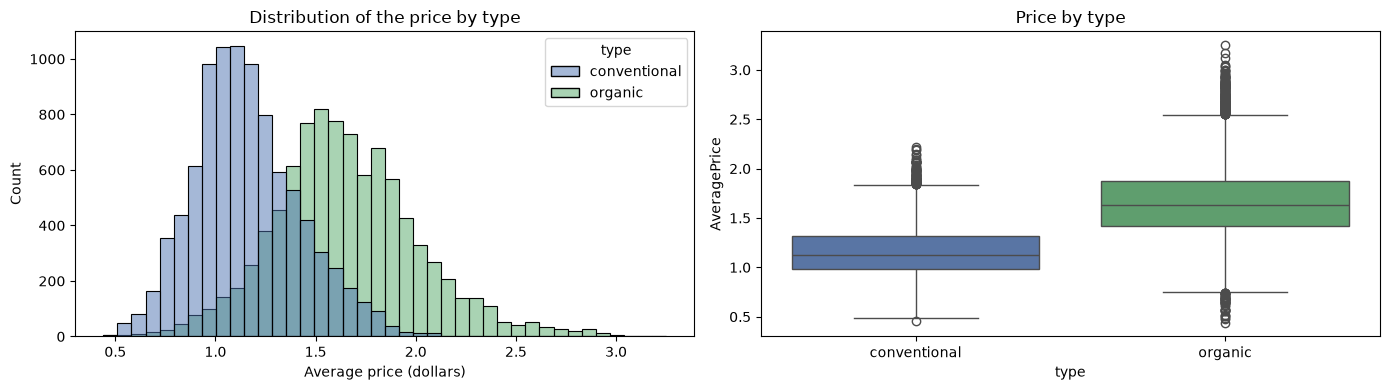

Imbalance (skew) of the price, 0 means symmetric: 0.58


In [6]:
print(avocado.groupby('type')['AveragePrice'].agg(['mean', 'median', 'std', 'count']).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=avocado, x='AveragePrice', hue='type', bins=40, ax=axes[0], palette=['#4c72b0', '#55a868'])
axes[0].set_title('Distribution of the price by type')
axes[0].set_xlabel('Average price (dollars)')
sns.boxplot(data=avocado, x='type', y='AveragePrice', ax=axes[1], hue='type', palette=['#4c72b0', '#55a868'], legend=False)
axes[1].set_title('Price by type')
plt.tight_layout()
plt.show()
print("Imbalance (skew) of the price, 0 means symmetric:", round(avocado['AveragePrice'].skew(), 2))

The histogram counts the weeks in each price band, one colour per type, and the box plot shows the middle half of each type as a box, its median as the line and the far values as dots. The two types are two different markets. A conventional avocado costs 1.16 dollars on average with a median of 1.13, and an organic one 1.65 with a median of 1.63, half a dollar more, and the two histograms overlap only in the 1.2 to 1.6 band. The type alone explains a large share of the price and it will be the first thing any tree asks. The skew of 0.58 says the overall price has a mild tail to the right, which is the organic peaks, and no transformation is needed for a tree.

type   conventional  organic
month                       
1             1.069    1.553
2             1.017    1.531
3             1.126    1.538
4             1.142    1.606
5             1.090    1.604
6             1.149    1.670
7             1.212    1.712
8             1.235    1.790
9             1.295    1.851
10            1.349    1.810
11            1.206    1.705
12            1.077    1.585

year
2015    1.376
2016    1.339
2017    1.515
2018    1.348
Name: AveragePrice, dtype: float64


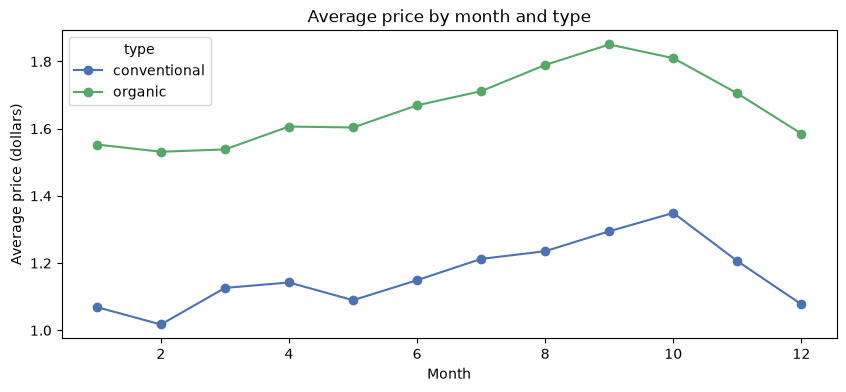

In [7]:
# Month and week of the year extracted from the date
avocado['month'] = avocado['Date'].dt.month
avocado['week'] = avocado['Date'].dt.isocalendar().week.astype(int)

by_month = avocado.groupby(['month', 'type'])['AveragePrice'].mean().unstack()
print(by_month.round(3))
print()
print(avocado.groupby('year')['AveragePrice'].mean().round(3))

fig, ax = plt.subplots(figsize=(10, 4))
by_month.plot(ax=ax, marker='o', color=['#4c72b0', '#55a868'])
ax.set_xlabel('Month')
ax.set_ylabel('Average price (dollars)')
ax.set_title('Average price by month and type')
plt.show()

The line chart draws the average price of each month, one line per type. Both lines share the same shape: cheapest in February, at 1.27 dollars overall, then climbing through the summer to a peak in September and October at 1.57 and 1.58, and falling back in December. That is the harvest calendar, since the Mexican crop that supplies the winter is abundant and the late summer relies on California. The gap between the two lines stays close to half a dollar all year, so the season and the type add up rather than interact. Across years the price was 1.38 in 2015, 1.34 in 2016, jumped to 1.52 in 2017, a year of a short crop, and sits at 1.35 in the first twelve weeks of 2018, which are winter weeks. The month and the week are kept as predictors, and the year too, with the warning that the 2018 rows only cover the cheap season.

Five cheapest regions
region
Houston             1.048
DallasFtWorth       1.086
SouthCentral        1.101
CincinnatiDayton    1.209
Nashville           1.212
Name: AveragePrice, dtype: float64

Five most expensive regions
region
Sacramento             1.622
Philadelphia           1.632
NewYork                1.728
SanFrancisco           1.804
HartfordSpringfield    1.819
Name: AveragePrice, dtype: float64


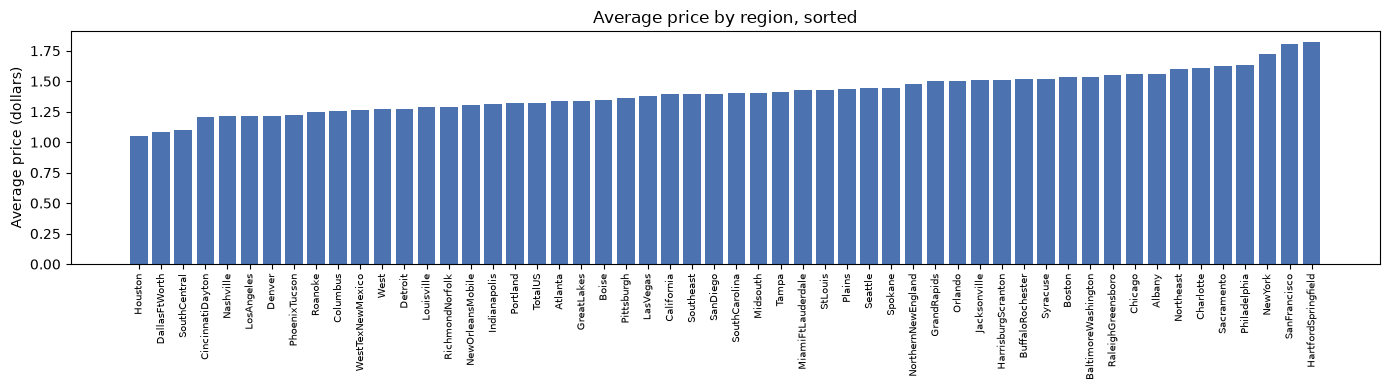

In [8]:
by_region = avocado.groupby('region')['AveragePrice'].mean().sort_values()
print("Five cheapest regions")
print(by_region.head(5).round(3))
print()
print("Five most expensive regions")
print(by_region.tail(5).round(3))

plt.figure(figsize=(14, 4))
plt.bar(by_region.index, by_region.values, color='#4c72b0')
plt.xticks(rotation=90, fontsize=7)
plt.ylabel('Average price (dollars)')
plt.title('Average price by region, sorted')
plt.tight_layout()
plt.show()

The bar chart sorts the 54 regions by their average price. Houston is the cheapest at 1.05 dollars and Dallas and the South Central aggregate follow at 1.09 and 1.10, all close to the Mexican border where most of the fruit enters. Hartford and Springfield are the most expensive at 1.82, then San Francisco at 1.80 and New York at 1.73. The spread between the cheapest and the dearest region is 0.77 dollars, larger than the gap between types, so the region has to be a predictor. It is text with 54 values, and a tree cannot split on text, so it is encoded below as 54 columns of 0 or 1, one per region. A tree handles that encoding well because it can ask "is this Houston" as a single split.

Pearson correlation with the price
Total Volume   -0.193
4046           -0.208
4225           -0.173
4770           -0.179
Total Bags     -0.177
Small Bags     -0.175
Large Bags     -0.173
XLarge Bags    -0.118
Name: AveragePrice, dtype: float64

Spearman correlation with the price
Total Volume   -0.612
4046           -0.596
4225           -0.514
4770           -0.533
Total Bags     -0.597
Small Bags     -0.536
Large Bags     -0.511
XLarge Bags    -0.427
Name: AveragePrice, dtype: float64


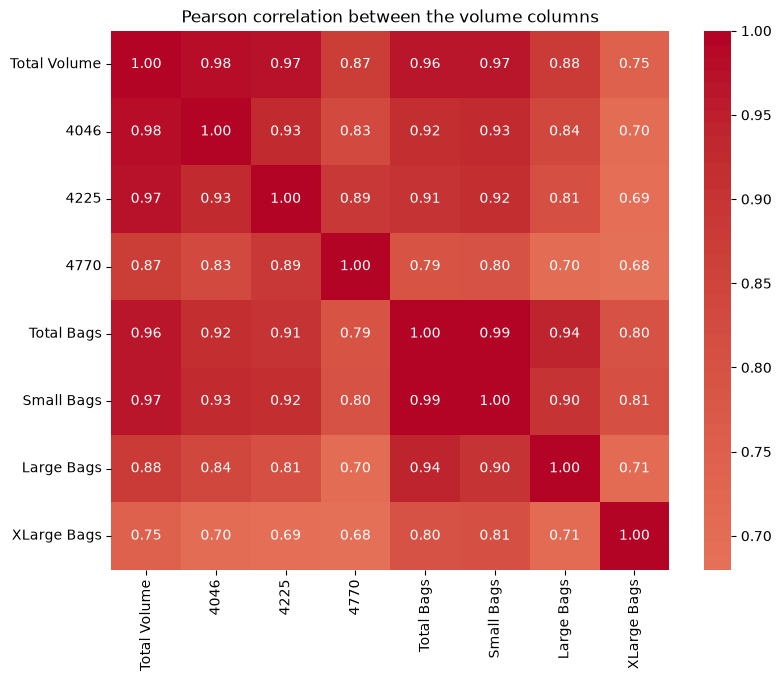

In [9]:
VOLUME_COLUMNS = ['Total Volume', '4046', '4225', '4770', 'Total Bags', 'Small Bags', 'Large Bags', 'XLarge Bags']

print("Pearson correlation with the price")
print(avocado[VOLUME_COLUMNS + ['AveragePrice']].corr()['AveragePrice'].drop('AveragePrice').round(3))
print()
print("Spearman correlation with the price")
print(avocado[VOLUME_COLUMNS + ['AveragePrice']].corr(method='spearman')['AveragePrice'].drop('AveragePrice').round(3))

plt.figure(figsize=(9, 7))
sns.heatmap(avocado[VOLUME_COLUMNS].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Pearson correlation between the volume columns')
plt.show()

Pearson measures how close each relationship is to a straight line and Spearman whether the ranking of one variable follows the ranking of the other. Against the price the two disagree strongly: Pearson gives every volume a weak correlation between -0.12 and -0.21, while Spearman gives -0.61 for `Total Volume` and between -0.43 and -0.60 for the rest. That gap is the signature of a relationship that is real but not a straight line. Weeks with more avocados sold are cheaper weeks, which is supply and demand, but the volumes run from a hundred to sixty million, so a straight line through them is dominated by the handful of national aggregate rows. A tree, which only orders the values, sees the Spearman version.

The heatmap shows that the eight volume columns are nearly one column. `Total Volume` correlates at 0.98 with `4046`, 0.97 with `4225` and 0.96 with `Total Bags`, and the bag columns correlate at 0.99 among themselves, because a region that sells many avocados sells many of every kind. For a linear regression this would be the multicollinearity problem seen in other notebooks of this project, with slopes that cannot be separated. A forest does not fit slopes, so its predictions are not hurt by it, but there is a consequence to keep in mind when reading the importances later: the trees pick whichever of the eight columns happens to be available at each split, so the importance of the volume is shared out among them and no single one looks large.

In [10]:
# Type as 0 or 1 and region as one 0 or 1 column per region
avocado['type_organic'] = (avocado['type'] == 'organic').astype(int)
encoded = pd.get_dummies(avocado.drop(columns=['Date', 'type']), columns=['region'], dtype=int)

REGION_COLUMNS = [c for c in encoded.columns if c.startswith('region_')]
FEATURES = VOLUME_COLUMNS + ['year', 'month', 'week', 'type_organic'] + REGION_COLUMNS
TARGET = 'AveragePrice'
print("Number of predictors:", len(FEATURES))
encoded[FEATURES].head()

Number of predictors: 66


,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,year,month,...,region_SouthCarolina,region_SouthCentral,region_Southeast,region_Spokane,region_StLouis,region_Syracuse,region_Tampa,region_TotalUS,region_West,region_WestTexNewMexico
0,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,2015,12,...,0,0,0,0,0,0,0,0,0,0
1,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,2015,12,...,0,0,0,0,0,0,0,0,0,0
2,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,2015,12,...,0,0,0,0,0,0,0,0,0,0
3,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,2015,12,...,0,0,0,0,0,0,0,0,0,0
4,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,2015,11,...,0,0,0,0,0,0,0,0,0,0


The table is now entirely numeric with 66 predictors: the eight volumes, the year, the month, the week, the type as 1 for organic, and 54 region columns. The `Date` column is dropped because its information is now in the year, month and week, and it would not be a valid predictor anyway since every future date is a value the model has never seen.

In [11]:
# 75 / 25 random split, the literal task
X = encoded[FEATURES]
y = encoded[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
print("Training weeks:", len(X_train))
print("Test weeks:", len(X_test))

Training weeks: 13686
Test weeks: 4563


The split leaves 13,686 rows for training and 4,563 for testing, chosen at random. A random split is the standard evaluation, but this file is a set of time series, one per region and type, so a random test row usually has its neighbouring weeks in the training set, which makes the task easier than predicting a week that has not happened yet. The evaluation section repeats the measurement with a split by time to show the difference.

## Machine Learning Model (CRISP-DM 4: Modeling)

Two models are grown on the same training rows. Model A is a single decision tree, first without any limit and then with a limit on its depth, to show what a tree does on its own. Model B is the random forest.

### Model A: a single decision tree

In [12]:
def report(name, model, X_eval, y_eval):
    predicted = model.predict(X_eval)
    return pd.Series({
        'R2': r2_score(y_eval, predicted),
        'MAE (dollars)': mean_absolute_error(y_eval, predicted),
        'RMSE (dollars)': np.sqrt(mean_squared_error(y_eval, predicted)),
    }, name=name)

# An unlimited tree, then a tree cut at ten levels
tree_full = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train, y_train)
TREE_DEPTH = 10
tree_limited = DecisionTreeRegressor(max_depth=TREE_DEPTH, random_state=RANDOM_STATE).fit(X_train, y_train)

print("Depth reached by the unlimited tree:", tree_full.get_depth())
tree_scores = pd.concat([
    report('Unlimited tree, training', tree_full, X_train, y_train),
    report('Unlimited tree, test', tree_full, X_test, y_test),
    report('Tree of depth 10, training', tree_limited, X_train, y_train),
    report('Tree of depth 10, test', tree_limited, X_test, y_test),
], axis=1).round(3)
print(tree_scores)

Depth reached by the unlimited tree: 38
                Unlimited tree, training  Unlimited tree, test  \
R2                                   1.0                 0.799   
MAE (dollars)                        0.0                 0.116   
RMSE (dollars)                       0.0                 0.180   

                Tree of depth 10, training  Tree of depth 10, test  
R2                                   0.814                   0.749  
MAE (dollars)                        0.122                   0.146  
RMSE (dollars)                       0.174                   0.201  


R-squared is the share of the variation of the price that the model explains, from 0 to 1, the mean absolute error is the average miss in dollars and the root mean squared error weighs the large misses more. The table compares each tree on the rows it was grown on and on the rows it never saw.

The unlimited tree grows 38 levels deep and reaches a training R-squared of 1.000 with an error of 0.000 dollars: it has split the rows until every leaf holds one week, so it repeats every training price exactly. On the test rows it drops to 0.799 with an average miss of 0.116 dollars. That gap between a perfect training score and a much lower test score is memorisation, which the course calls overfitting. Cutting the tree at ten levels brings training and test closer, 0.814 against 0.749, so it memorises less, but it also explains less. A single tree cannot have both, and that is the reason the forest exists.

### Model B: random forest

In [13]:
# Two hundred trees, each grown on a random sample of the rows with a random
# subset of the predictors at every split. min_samples_leaf stops a leaf from
# holding fewer than three weeks, which keeps the saved model small
N_TREES = 200
MIN_LEAF = 3
forest = RandomForestRegressor(n_estimators=N_TREES, min_samples_leaf=MIN_LEAF, oob_score=True,
                               random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)

forest_scores = pd.concat([
    report('Forest, training', forest, X_train, y_train),
    report('Forest, test', forest, X_test, y_test),
], axis=1).round(3)
print(forest_scores)
print()
print("Out-of-bag R2:", round(forest.oob_score_, 3))

                Forest, training  Forest, test
R2                         0.968         0.898
MAE (dollars)              0.048         0.091
RMSE (dollars)             0.072         0.128

Out-of-bag R2: 0.893


The forest reaches an R-squared of 0.898 on the test rows with an average miss of 0.091 dollars, against 0.799 and 0.116 for the best single tree. The training score is 0.968, so the forest still fits its own rows more closely than new ones, but the gap has narrowed and the test error dropped by a quarter. Each tree in the forest is grown on a sample drawn with replacement, which leaves about a third of the rows out of every tree, and the out-of-bag score is the R-squared computed on those left-out rows by the trees that did not see them. Its value of 0.893 agrees with the test score, which is a second confirmation that 0.9 is the honest accuracy of the forest on a random split.

type_organic           0.396
4046                   0.083
Large Bags             0.080
year                   0.065
4225                   0.064
week                   0.061
month                  0.043
Small Bags             0.033
Total Bags             0.031
4770                   0.030
Total Volume           0.028
region_SanFrancisco    0.014
dtype: float64

Importance of the 54 region columns together: 0.08
Importance of the 8 volume columns together: 0.355


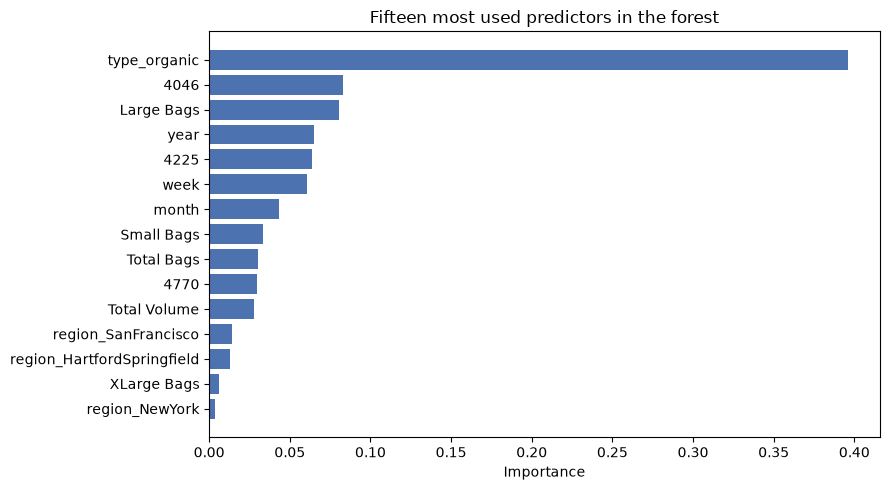

In [14]:
# Which predictors the forest used most. The importance of a predictor is the
# share of the price variation that the splits on it removed, summed over the trees
importance = pd.Series(forest.feature_importances_, index=FEATURES).sort_values(ascending=False)
print(importance.head(12).round(3))
print()
print("Importance of the 54 region columns together:", round(importance[REGION_COLUMNS].sum(), 3))
print("Importance of the 8 volume columns together:", round(importance[VOLUME_COLUMNS].sum(), 3))

plt.figure(figsize=(9, 5))
top = importance.head(15)
plt.barh(top.index[::-1], top.values[::-1], color='#4c72b0')
plt.xlabel('Importance')
plt.title('Fifteen most used predictors in the forest')
plt.tight_layout()
plt.show()

The bar chart ranks the predictors by importance, which is the share of the price variation the splits on that predictor removed, summed over all trees, so that the importances add up to 1. The type is first at 0.40, as the exploration predicted, and no other predictor comes close. Then come `4046` at 0.08 and `Large Bags` at 0.08, the year, `4225`, the week and the month between 0.04 and 0.07, and the remaining volume columns.

The two sums explain the picture. The eight volume columns together hold 0.36 of the importance, almost as much as the type, but shared among eight nearly identical columns none of them ranks high on its own, which is the effect the correlation section warned about. The 54 region columns together hold 0.08 even though the region spreads the price over 0.77 dollars, and that is because the region is also written in the volumes: a region sells a characteristic quantity of avocados every week, so the trees can identify Houston from its volume without ever asking the Houston column.

## Evaluation (CRISP-DM 5)

The forest is evaluated on the random test rows, with the plots that show where it misses, and then on a split by time that answers the question a grocer would actually ask.

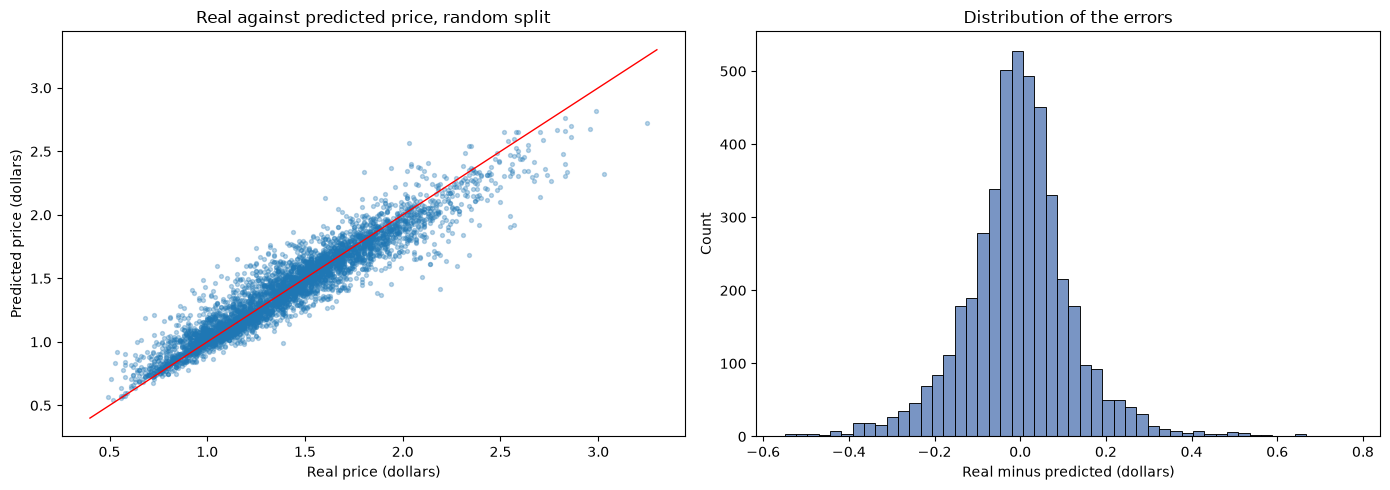

Imbalance (skew) of the errors: 0.23
Share of test weeks missed by more than 0.25 dollars: 6.2 %


In [15]:
predicted_test = forest.predict(X_test)
residuals = y_test - predicted_test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, predicted_test, alpha=0.3, s=8)
axes[0].plot([0.4, 3.3], [0.4, 3.3], color='red', linewidth=1)
axes[0].set_xlabel('Real price (dollars)')
axes[0].set_ylabel('Predicted price (dollars)')
axes[0].set_title('Real against predicted price, random split')
sns.histplot(residuals, bins=50, ax=axes[1], color='#4c72b0')
axes[1].set_xlabel('Real minus predicted (dollars)')
axes[1].set_title('Distribution of the errors')
plt.tight_layout()
plt.show()
print("Imbalance (skew) of the errors:", round(residuals.skew(), 2))
print("Share of test weeks missed by more than 0.25 dollars:", round((residuals.abs() > 0.25).mean() * 100, 1), "%")

Each dot in the left panel is a test week placed by its real and its predicted price, and the red diagonal is a perfect prediction. The cloud hugs the diagonal from 0.6 to 2.2 dollars and thins out above, where the few weeks priced above 2.5 dollars are predicted lower than they were, because a forest averages leaves and an average never reaches the extremes. The histogram of the errors is a narrow bell centred on zero, and its skew of 0.23 confirms a light tail to the right, made of those underpredicted expensive weeks. Only 6.2 percent of the test weeks are missed by more than a quarter of a dollar.

In [16]:
# Split by time: grow the forest on 2015 to 2017 and predict the twelve weeks of 2018
LAST_TRAINING_YEAR = 2017
past = encoded[encoded['year'] <= LAST_TRAINING_YEAR]
future = encoded[encoded['year'] > LAST_TRAINING_YEAR]
print("Training weeks up to 2017:", len(past), " Test weeks of 2018:", len(future))

forest_time = RandomForestRegressor(n_estimators=N_TREES, min_samples_leaf=MIN_LEAF,
                                    random_state=RANDOM_STATE, n_jobs=-1).fit(past[FEATURES], past[TARGET])
tree_time = DecisionTreeRegressor(max_depth=TREE_DEPTH, random_state=RANDOM_STATE).fit(past[FEATURES], past[TARGET])

time_scores = pd.concat([
    report('Tree of depth 10, 2018', tree_time, future[FEATURES], future[TARGET]),
    report('Forest, 2018', forest_time, future[FEATURES], future[TARGET]),
], axis=1).round(3)
print(time_scores)
print()
print("Mean price 2015 to 2017:", round(past[TARGET].mean(), 3), " Mean price 2018:", round(future[TARGET].mean(), 3))

Training weeks up to 2017: 16953  Test weeks of 2018: 1296


                Tree of depth 10, 2018  Forest, 2018
R2                               0.036         0.410
MAE (dollars)                    0.238         0.188
RMSE (dollars)                   0.300         0.235

Mean price 2015 to 2017: 1.41  Mean price 2018: 1.348


This is the honest measurement. Grown on 2015 to 2017 and asked about the 1,296 weeks of 2018, the forest reaches an R-squared of 0.410 and an average miss of 0.188 dollars, twice the miss of the random split, and the single tree collapses to 0.036, which is no better than answering the average price to every question. The forest has never seen a row with year 2018 and can only treat it as 2017, the most expensive year in the file, while the early weeks of 2018 were cheap, with a mean of 1.35 against 1.41 for the training years.

The random split hides this because for each test week the same region and type has its neighbouring weeks in training, and the forest is interpolating between them. That is fine for filling a gap in a table, and it is what the literal task measured, but it is not forecasting. The forest is still usable for a week close to the data it has seen, and it is clearly better than a tree, but a price for a week far in the future needs a time series model, and the bitcoin notebook of this project shows that technique.

## Results (CRISP-DM 6: Deployment)

The model kept is a random forest of 200 trees with at least three weeks per leaf, grown on 66 predictors: the eight sales volumes, the year, the month, the week, the type and the 54 region indicators. On the random 25 percent test split it reaches an R-squared of 0.898, a mean absolute error of 0.091 dollars and a root mean squared error of 0.128, and its out-of-bag score of 0.893 agrees. The single decision tree, built first as the baseline, memorises its training rows perfectly and drops to 0.799 on the test rows, or 0.749 when cut at ten levels, so the forest removes a quarter of the tree's error and the choice between them is not close.

The type of avocado is the predictor that matters most, worth 0.40 of the importance and about half a dollar of price, followed by the volumes sold, which together weigh as much as the type but are spread over eight nearly identical columns, and by the calendar. The region weighs little on its own because the volumes already identify it.

The limitation is time. Evaluated on the weeks of 2018 after training on the earlier years, the R-squared falls to 0.410 and the average miss to 0.19 dollars, because the forest cannot extrapolate to a year it has not seen. The model is recommended for the assistant as a lookup of the expected price of a given region, type and season, with an error near nine cents, and not as a forecast of next season's price. It is saved below with its predictor list, the region columns and the type encoding, so the REST API can build the same 66 columns and predict without training.

In [17]:
bundle = {
    'model': forest,
    'features': FEATURES,
    'target': TARGET,
    'region_columns': REGION_COLUMNS,
    'volume_columns': VOLUME_COLUMNS,
    'type_encoding': {'conventional': 0, 'organic': 1},
}
MODEL_PATH = os.path.join(MODELS_DIR, 'avocado_price_regression.joblib')
joblib.dump(bundle, MODEL_PATH, compress=3)
print("Saved to", MODEL_PATH, " size: %.1f MB" % (os.path.getsize(MODEL_PATH) / 1e6))

Saved to ../../models/avocado_price_regression.joblib  size: 20.3 MB


In [18]:
# Reload and predict one week by hand: organic avocados in San Francisco, the
# second week of September 2017, with the volumes that region and type sold
# in a typical week of that month
loaded = joblib.load(MODEL_PATH)
example_region = 'SanFrancisco'
september = avocado[(avocado['region'] == example_region) & (avocado['type'] == 'organic') &
                    (avocado['year'] == 2017) & (avocado['month'] == 9)]
typical = september[VOLUME_COLUMNS].median()

week_row = pd.DataFrame([dict.fromkeys(loaded['features'], 0.0)])
for column in VOLUME_COLUMNS:
    week_row.loc[0, column] = typical[column]
week_row.loc[0, ['year', 'month', 'week', 'type_organic']] = [2017, 9, 37, loaded['type_encoding']['organic']]
week_row.loc[0, 'region_' + example_region] = 1

print("Predicted price: %.2f dollars" % loaded['model'].predict(week_row)[0])
print("Real average of organic avocados in %s during September 2017: %.2f dollars" % (
    example_region, september['AveragePrice'].mean()))

Predicted price: 1.92 dollars
Real average of organic avocados in SanFrancisco during September 2017: 2.06 dollars


The reloaded forest prices an organic avocado in San Francisco in September 2017 at 1.92 dollars, against a real monthly average of 2.06, a miss of 14 cents on one of the most expensive combinations in the file, an expensive region in the expensive season of the expensive year, which is where the real against predicted plot showed the forest running low. This is the call the REST API will make: fill the 66 columns from the region, the type, the date and the volumes, and predict.